In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [52]:
df = pd.read_csv("F:\diabetes-risk-analysis\data\diabetes_risk.csv")
df.head()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low


In [53]:
df.shape

(15000, 19)

In [54]:
df.tail()

,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
14995,14996,47,Male,Mumbai,37.7,No,Sedentary,Non-Vegetarian,Never,Never,6.8,7,213,8.1,150,100,141.7,High,High
14996,14997,48,Female,Mumbai,20.6,No,Moderate,Non-Vegetarian,Never,NaN,6.0,8,162,6.5,132,80,91.0,NaN,Low
14997,14998,34,Female,Nagpur,17.9,No,Active,Vegetarian,Never,Never,7.0,6,137,6.5,136,90,88.8,Low,Low
14998,14999,56,Male,Ahmedabad,20.7,Yes,Active,Vegetarian,Never,Never,6.0,5,163,6.9,140,87,94.8,Low,Low
14999,15000,54,Male,Surat,34.5,No,Moderate,Vegetarian,Never,Never,7.4,2,186,7.2,150,88,130.4,Middle,Moderate


In [55]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   patient_id                15000 non-null  int64  
 1   age                       15000 non-null  int64  
 2   gender                    15000 non-null  object 
 3   city                      15000 non-null  object 
 4   bmi                       15000 non-null  float64
 5   family_history_diabetes   15000 non-null  object 
 6   physical_activity_level   15000 non-null  object 
 7   diet_type                 15000 non-null  object 
 8   smoking_status            14528 non-null  object 
 9   alcohol_consumption       11212 non-null  object 
 10  hours_sleep_per_night     15000 non-null  float64
 11  stress_level              15000 non-null  int64  
 12  fasting_blood_sugar       15000 non-null  int64  
 13  hba1c_level               15000 non-null  float64
 14  blood_

In [56]:
df.describe(include="object")

,gender,city,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,income_bracket,diabetes_risk
count,15000,15000,15000,15000,15000,14528,11212,14537,15000
unique,3,18,2,3,4,3,3,3,3
top,Male,Mumbai,No,Active,Non-Vegetarian,Never,Never,Middle,Low
freq,7664,2243,9756,5100,8195,10119,5616,7305,9000


In [57]:
df.nunique()

patient_id                  15000
age                            58
gender                          3
city                           18
bmi                           239
family_history_diabetes         2
physical_activity_level         3
diet_type                       4
smoking_status                  3
alcohol_consumption             3
hours_sleep_per_night          73
stress_level                   10
fasting_blood_sugar           273
hba1c_level                    71
blood_pressure_systolic        89
blood_pressure_diastolic       58
waist_circumference_cm        614
income_bracket                  3
diabetes_risk                   3
dtype: int64

In [58]:
df.dtypes

patient_id                    int64
age                           int64
gender                       object
city                         object
bmi                         float64
family_history_diabetes      object
physical_activity_level      object
diet_type                    object
smoking_status               object
alcohol_consumption          object
hours_sleep_per_night       float64
stress_level                  int64
fasting_blood_sugar           int64
hba1c_level                 float64
blood_pressure_systolic       int64
blood_pressure_diastolic      int64
waist_circumference_cm      float64
income_bracket               object
diabetes_risk                object
dtype: object

In [59]:
missing = df.isnull().sum()
missing[missing > 0]

smoking_status          472
alcohol_consumption    3788
income_bracket          463
dtype: int64

In [60]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100})

missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

In [61]:
df["smoking_status"] = df["smoking_status"].fillna("Unknown")
df["income_bracket"] = df["income_bracket"].fillna("Unknown")
df["alcohol_consumption"] = df["alcohol_consumption"].fillna("Unknown")

In [62]:
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [63]:
print("Total records:", len(df))
print("Unique patient IDs:", df["patient_id"].nunique())

Total records: 15000
Unique patient IDs: 15000


In [64]:
categorical_columns = df.select_dtypes(include="object").columns
for columns in categorical_columns:
    print("\n", columns)
    print(df[columns].value_counts(dropna=False))


 gender
gender
Male      7664
Female    7183
Other      153
Name: count, dtype: int64

 city
city
Mumbai           2243
Delhi            1737
Bengaluru        1535
Hyderabad        1227
Ahmedabad        1039
Chennai           933
Kolkata           872
Pune              756
Surat             734
Jaipur            627
Kanpur            475
Nagpur            462
Indore            458
Lucknow           457
Thane             451
Bhopal            399
Visakhapatnam     307
Patna             288
Name: count, dtype: int64

 family_history_diabetes
family_history_diabetes
No     9756
Yes    5244
Name: count, dtype: int64

 physical_activity_level
physical_activity_level
Active       5100
Sedentary    4950
Moderate     4950
Name: count, dtype: int64

 diet_type
diet_type
Non-Vegetarian    8195
Vegetarian        6074
Pescatarian        445
Vegan              286
Name: count, dtype: int64

 smoking_status
smoking_status
Never      10119
Current     2946
Former      1463
Unknown      472
Name: cou

In [65]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
patient_id,15000.0,7500.500000,4330.271354,1.0,3750.75,7500.5,11250.25,15000.0
age,15000.0,44.333667,10.383753,18.0,38.00,45.0,52.00,80.0
bmi,15000.0,23.062260,4.046391,15.0,20.10,22.7,25.60,40.8
hours_sleep_per_night,15000.0,7.309860,1.109372,3.0,6.70,7.0,8.00,12.0
stress_level,15000.0,5.941200,2.148406,1.0,4.00,6.0,7.00,10.0
fasting_blood_sugar,15000.0,168.789933,38.365822,72.0,145.00,165.0,189.00,400.0
hba1c_level,15000.0,6.878387,0.843276,4.8,6.30,6.8,7.30,13.4
blood_pressure_systolic,15000.0,139.496200,12.660785,80.0,130.00,140.0,150.00,200.0
blood_pressure_diastolic,15000.0,86.256933,8.386529,50.0,80.00,88.0,90.00,120.0
waist_circumference_cm,15000.0,100.207933,10.760331,73.2,92.50,99.3,106.90,148.2


In [66]:
print("Age Range", df["age"].min(), "-", df["age"].max())
print("BMI Range", df["bmi"].min(), "-", df["bmi"].max())
print("Sleep Range", df["hours_sleep_per_night"].min(), "-", df["hours_sleep_per_night"].max())

Age Range 18 - 80
BMI Range 15.0 - 40.8
Sleep Range 3.0 - 12.0


In [67]:
numerical_columns = [
    "age",
    "bmi",
    "hours_sleep_per_night",
    "stress_level",
    "fasting_blood_sugar",
    "hba1c_level",
    "blood_pressure_systolic",
    "blood_pressure_diastolic",
    "waist_circumference_cm"
]

In [68]:
outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_summary.append({
        "Column": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers Count": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count
0,age,38.0,52.0,14.0,17.00,73.00,3
1,bmi,20.1,25.6,5.5,11.85,33.85,153
2,hours_sleep_per_night,6.7,8.0,1.3,4.75,9.95,360
3,stress_level,4.0,7.0,3.0,-0.50,11.50,0
4,fasting_blood_sugar,145.0,189.0,44.0,79.00,255.00,432
5,hba1c_level,6.3,7.3,1.0,4.80,8.80,355
6,blood_pressure_systolic,130.0,150.0,20.0,100.00,180.00,11
7,blood_pressure_diastolic,80.0,90.0,10.0,65.00,105.00,213
8,waist_circumference_cm,92.5,106.9,14.4,70.90,128.50,167


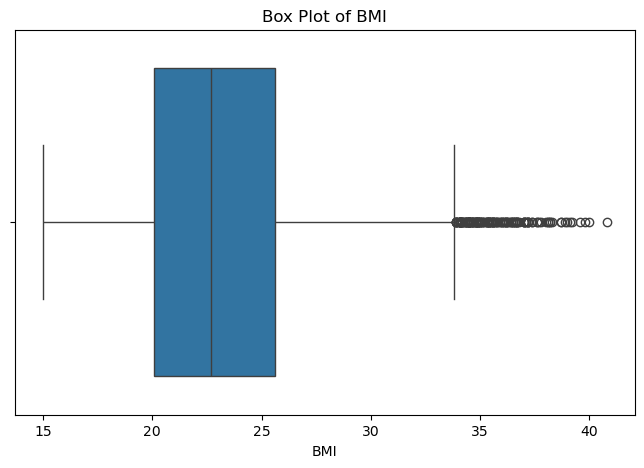

In [69]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["bmi"])
plt.title("Box Plot of BMI")
plt.xlabel("BMI")
plt.show();

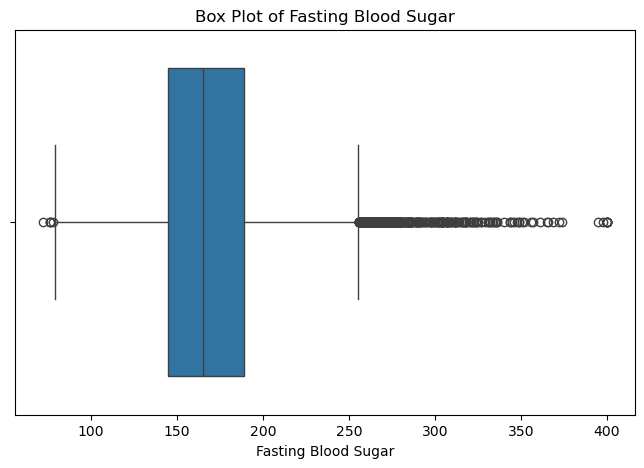

In [70]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["fasting_blood_sugar"])
plt.title("Box Plot of Fasting Blood Sugar")
plt.xlabel("Fasting Blood Sugar")
plt.show();

In [71]:
cleaned_df = df.copy()

In [72]:
cleaned_df["smoking_status"] = cleaned_df["smoking_status"].fillna("Unknown")
cleaned_df["alcohol_consumption"] = cleaned_df["alcohol_consumption"].fillna("Unknown")
cleaned_df["income_bracket"] = cleaned_df["income_bracket"].fillna("Unknown")

In [73]:
cleaned_df.isnull().sum()

patient_id                  0
age                         0
gender                      0
city                        0
bmi                         0
family_history_diabetes     0
physical_activity_level     0
diet_type                   0
smoking_status              0
alcohol_consumption         0
hours_sleep_per_night       0
stress_level                0
fasting_blood_sugar         0
hba1c_level                 0
blood_pressure_systolic     0
blood_pressure_diastolic    0
waist_circumference_cm      0
income_bracket              0
diabetes_risk               0
dtype: int64

In [74]:
print("Shape:", cleaned_df.shape)

print("\nMissing Values:")
print(cleaned_df.isnull().sum())

print("Duplicate Rows:")
print(cleaned_df.duplicated().sum())

print("Unique Patient IDs:")
print(cleaned_df["patient_id"].nunique())

Shape: (15000, 19)

Missing Values:
patient_id                  0
age                         0
gender                      0
city                        0
bmi                         0
family_history_diabetes     0
physical_activity_level     0
diet_type                   0
smoking_status              0
alcohol_consumption         0
hours_sleep_per_night       0
stress_level                0
fasting_blood_sugar         0
hba1c_level                 0
blood_pressure_systolic     0
blood_pressure_diastolic    0
waist_circumference_cm      0
income_bracket              0
diabetes_risk               0
dtype: int64
Duplicate Rows:
0
Unique Patient IDs:
15000


In [75]:
cleaned_df.to_csv("F:\diabetes-risk-analysis\data\cleaned_diabetes_risk.csv", index=False)